# 第 3 章 善用身边的数学秘书 —— 工具演示（Matlab → Python 对照）

对应笔记 `docs/mc/ch03.md`。五个演示：数组与向量化提速、线性代数、作图（含特殊坐标与 3D）、符号验算（sympy）、随机模拟常用函数速查。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch03")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2026)
print("numpy", np.__version__)

numpy 2.4.6


## 3.1/3.4 数组与向量化：同一个积分估计，循环 vs 向量

用平均值法估计 $\int_0^1 e^{-x^2}dx$：Python 循环写法与 NumPy 向量化写法，`%timeit` 对比。

In [2]:
def mean_loop(N):
    s = 0.0
    for _ in range(N):
        s += np.exp(-rng.random()**2)
    return s / N

def mean_vec(N):
    return np.exp(-rng.random(N)**2).mean()

N = 1_000_000
print(f"循环版   : {mean_loop(N):.6f}")
print(f"向量化版 : {mean_vec(N):.6f}")
%timeit -n3 -r3 mean_loop(100_000)
%timeit -n3 -r3 mean_vec(100_000)

循环版   : 0.747032
向量化版 : 0.746742
53.4 ms ± 2.03 ms per loop (mean ± std. dev. of 3 runs, 3 loops each)
609 μs ± 74.2 μs per loop (mean ± std. dev. of 3 runs, 3 loops each)


## 3.2 线性代数：解方程与特征值

$A\mathbf x=\mathbf b$ 的解法 `solve`（不要用求逆），特征值 `eig`。矩阵例：对称三对角阵。

In [3]:
A = np.diag(2*np.ones(4)) + np.diag(-np.ones(3), 1) + np.diag(-np.ones(3), -1)
b = np.array([1., 0., 0., 1.])
x = np.linalg.solve(A, b)
print("A =\n", A)
print("solve 验证 A@x-b =", A @ x - b)
w, V = np.linalg.eigh(A)
print("特征值:", np.round(w, 4))

A =
 [[ 2. -1.  0.  0.]
 [-1.  2. -1.  0.]
 [ 0. -1.  2. -1.]
 [ 0.  0. -1.  2.]]
solve 验证 A@x-b = [ 0.00000000e+00  0.00000000e+00 -2.22044605e-16  0.00000000e+00]
特征值: [0.382 1.382 2.618 3.618]


## 3.3 作图：二维、特殊坐标、三维

2×2 演示：曲线+散点、直方图、loglog（贴 $N^{-1/2}$）、极坐标玫瑰；再来一张 3D 曲面（二维正态密度）。

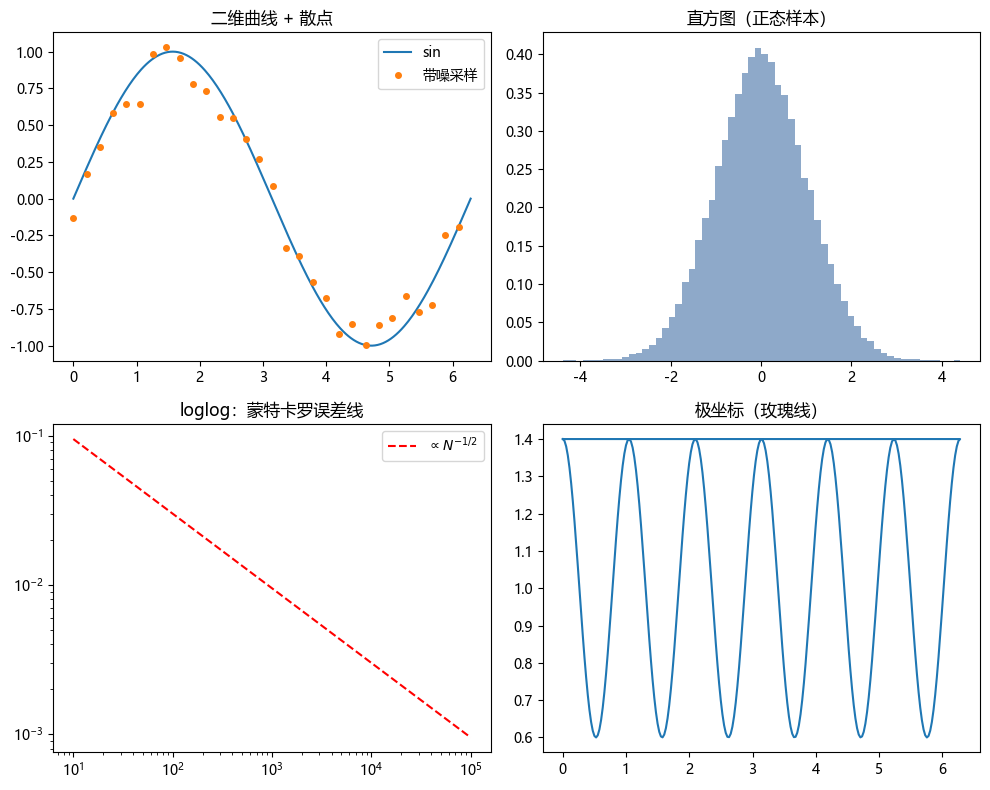

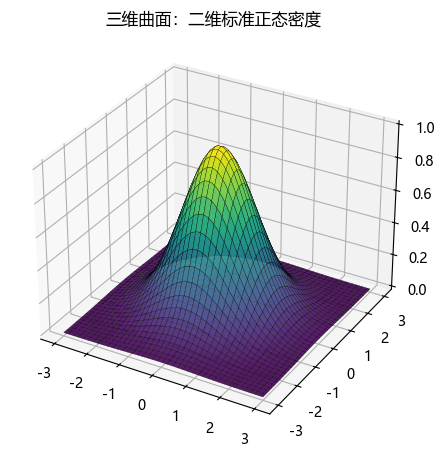

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
xx = np.linspace(0, 2*np.pi, 300)
axes[0, 0].plot(xx, np.sin(xx), label="sin")
axes[0, 0].plot(xx[::10], np.sin(xx[::10]) + 0.12*rng.standard_normal(30), "o", ms=4, label="带噪采样")
axes[0, 0].legend(); axes[0, 0].set_title("二维曲线 + 散点")
axes[0, 1].hist(rng.normal(0, 1, 50_000), bins=60, density=True, color="#8ea9c9")
axes[0, 1].set_title("直方图（正态样本）")
Nn = np.geomspace(10, 1e5, 200)
axes[1, 0].loglog(Nn, 0.3/np.sqrt(Nn), "r--", label=r"$\propto N^{-1/2}$")
axes[1, 0].set_title("loglog：蒙特卡罗误差线"); axes[1, 0].legend()
phi = np.linspace(0, 2*np.pi, 240)
r = 1 + 0.4*np.cos(6*phi)
axes[1, 1].plot(np.r_[phi, phi[0]], np.r_[r, r[0]])
axes[1, 1].set_title("极坐标（玫瑰线）")
fig.tight_layout(); save(fig, "out-plot-demo.png"); plt.show()

from matplotlib import cm
xg = np.linspace(-3, 3, 80)
XG, YG = np.meshgrid(xg, xg)
ZG = np.exp(-(XG**2 + YG**2)/2)
fig3 = plt.figure(figsize=(6.4, 4.6))
ax3 = fig3.add_subplot(projection="3d")
ax3.plot_surface(XG, YG, ZG, cmap=cm.viridis, lw=0.2, edgecolor="k", alpha=0.9)
ax3.set_title("三维曲面：二维标准正态密度")
fig3.tight_layout(); save(fig3, "out-3d.png"); plt.show()

## 3.5 符号演算：sympy 验算前面的推导

验算蒲丰投针积分（1.4）与 $U^2$ 变换密度（2.5），再解个方程。

In [6]:
import sympy as sp
th, L, D, u = sp.symbols("theta L D u", positive=True)
x = sp.symbols("x")                                     # 允许负根

I = sp.integrate(L*sp.sin(th)/D * 1/sp.pi, (th, 0, sp.pi))
print("蒲丰积分 =", sp.simplify(I))                      # 2L/(πD)

fy = sp.diff(sp.sqrt(u), u)                              # F_Y(y)=√y 求导
print("Y=U² 的密度 =", fy)                               # 1/(2√u)
print("归一化检验 =", sp.integrate(1/(2*sp.sqrt(u)), (u, 0, 1)))

print("方程 x²+x-6=0 的根:", sp.solve(sp.Eq(x**2 + x - 6, 0), x))

蒲丰积分 = 2*L/(pi*D)
Y=U² 的密度 = 1/(2*sqrt(u))
归一化检验 = 1
方程 x²+x-6=0 的根: [-3, 2]


## 随机模拟常用函数速查（NumPy Generator）

| 抽什么 | 调用 |
|---|---|
| 均匀 $U(0,1)$ | `rng.random(n)` |
| 整数 | `rng.integers(low, high, size)` |
| 正态 | `rng.normal(mu, sigma, size)` |
| 指数 | `rng.exponential(scale, size)` |
| 序列抽样/加权 | `rng.choice(a, size, p=)` |
| 洗牌 | `rng.permutation(x)` |
| 指定种子 | `np.random.default_rng(seed)` |

第 4 章拆开 `default_rng` 内部（Mersenne Twister），第 5 章自己动手把这些分布从均匀随机数造出来。